**PART 2.  POOLING AND THE WHOLE CNN**

2.1  POOLING
-------------------------------------------------------------
Pooling shrinks a feature map by summarising each small block with ONE number.
  - MAX POOLING 2x2, stride 2: take the biggest of each 2x2 block.
  - AVERAGE POOLING: take the mean of the block.
Why: (1) fewer numbers for the next layer, (2) the network becomes less
sensitive to a feature moving by one pixel, (3) it has NO learnable parameters.

  EX 5 (paper, 5 min).  Max pooling, 2x2, stride 2, on this 4 x 4 map:

         1  3  2  1
         4  6  5  2
         7  2  9  0
         1  8  3  4

  Write the 2 x 2 result.  (Each block of 4 numbers gives one number.)

	     6  5
	     8  9


2.2  THE CNN RECIPE
-------------------------------------------------------------
        [ Conv -> ReLU -> Pool ]  repeated  ->  Flatten  ->  Linear
  - Conv + ReLU: find local patterns.  ReLU (Day 14) adds the non-linearity;
    without it, stacked convolutions collapse into one linear operation.
  - Pool: shrink.
  - Flatten + Linear: use all the detected features to decide the class.
  - Tensor shape in PyTorch is (N, C, H, W):
        N = batch size, C = channels, H = height, W = width.
    (Your Day 16 inputs were (N, 64): no C, H or W.)

  A small CNN for 28 x 28 grey images (10 classes):

        nn.Conv2d(1, 8, 3, padding=1)    nn.ReLU()    nn.MaxPool2d(2)
        nn.Conv2d(8, 16, 3, padding=1)   nn.ReLU()    nn.MaxPool2d(2)
        nn.Flatten()                      nn.Linear(784, 10)

  EX 6 (paper, 10 min).  The SHAPE DETECTIVE.  Fill the shape after each layer
  (batch size N stays N; write (N, C, H, W)) and the parameters of each layer.

        layer                          output shape          parameters
        input                          (N, 1,  28, 28)           -
        Conv2d(1, 8, 3, padding=1)     (N, 1,  28, 28)           80
        ReLU                           (N, 8,  28, 28)           -
        MaxPool2d(2)                   (N, 8,  14, 14)           -
        Conv2d(8, 16, 3, padding=1)    (N, 16, 14, 14)           1168
        ReLU                           (N, 16, 14, 14)           -
        MaxPool2d(2)                   (N, 16, 7,  7)            -
        Flatten                        (N, 784)                  -
        Linear(784, 10)                (N, 7850)                 7850
        TOTAL parameters: 9098  

  Where does 784 come from?  16 x 7 x 7 = 784.

  CHECK IN COLAB (this is the code, not a task to write from scratch):

        import torch, torch.nn as nn
        model = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(784, 10))
        x = torch.zeros(4, 1, 28, 28)
        for layer in model:
            x = layer(x)
            print(layer.__class__.__name__, tuple(x.shape))
        print(sum(p.numel() for p in model.parameters()))

  If your paper shapes and the printed shapes disagree, the printed ones win;
  find the line where your paper went wrong.


In [1]:
import torch, torch.nn as nn
model = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), 
                      nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                      nn.Flatten(), nn.Linear(784, 10))
x = torch.zeros(4, 1, 28, 28)
for layer in model:
    x = layer(x)
    print(layer.__class__.__name__, tuple(x.shape))
print(sum(p.numel() for p in model.parameters()))

Conv2d (4, 8, 28, 28)
ReLU (4, 8, 28, 28)
MaxPool2d (4, 8, 14, 14)
Conv2d (4, 16, 14, 14)
ReLU (4, 16, 14, 14)
MaxPool2d (4, 16, 7, 7)
Flatten (4, 784)
Linear (4, 10)
9098


In [2]:
import numpy as np
def conv2d(img,  ker, stride=1, pad=0):
    img = np.pad(img, pad)
    n, k = img.shape[0], ker.shape[0]
    out_n = (n - k)//stride + 1
    out = np.zeros((out_n, out_n))
    for i in range((out_n)):
        for j in range(out_n):
            window = img[i*stride : i*stride + k,
                         j*stride : j*stride + k]
            out[i, j] = (window * ker).sum()
    return out

In [3]:
image = np.array([
    [0, 0, 1, 3, 3],
    [0, 1, 1, 3, 3],
    [0, 0, 2, 3, 3],
    [0, 1, 1, 3, 2],
    [0, 0, 1, 3, 3]
])

kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

print("--- Ex 1 Output (Stride 1) ---")
print(conv2d(image, kernel, stride=1, pad=0))

print("\n--- Ex 4 Output (Stride 2) ---")
print(conv2d(image, kernel, stride=2, pad=0))

print("\n--- Pad=1 Output (Stride 1) ---")
print(conv2d(image, kernel, stride=1, pad=1))

--- Ex 1 Output (Stride 1) ---
[[4. 8. 5.]
 [4. 7. 4.]
 [4. 8. 4.]]

--- Ex 4 Output (Stride 2) ---
[[4. 5.]
 [4. 4.]]

--- Pad=1 Output (Stride 1) ---
[[ 1.  2.  5.  4. -6.]
 [ 1.  4.  8.  5. -9.]
 [ 2.  4.  7.  4. -9.]
 [ 1.  4.  8.  4. -9.]
 [ 1.  2.  5.  3. -6.]]


2.4  WHY IS THIS BETTER THAN FLATTENING?  (for your notes)
-------------------------------------------------------------
  - LOCAL CONNECTIONS: each output looks at a small patch only.
  - WEIGHT SHARING: the same 3 x 3 kernel is reused at every position, so the
    parameter count does not grow with the image size.
  - SHIFT TOLERANCE: a feature is found wherever it appears (pooling helps).
  Link to Day 16: your best digit model had 4,810 parameters.  A CNN for the same
  8 x 8 digits:
        Conv2d(1, 8, 3, padding=1) -> ReLU -> MaxPool2d(2) -> Flatten -> Linear(128, 10)
  has 80 + 1,290 = 1,370 parameters and sees the 2D structure (input shape
  (N, 1, 8, 8) instead of (N, 64)).

  OPTIONAL (only if you have 30 spare minutes, Colab): take your Day 16 digit
  classifier, reshape the inputs to (N, 1, 8, 8), swap the model for the CNN
  above, keep everything else, and compare the test accuracy (Day 16 test:
  0.9639).  Do not change anything else, so the comparison is fair.

In [4]:
import copy, os
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

#PART 1. DATA
d = load_digits()
X, y = d.data, d.target
print(X.shape, X.min(), X.max())
print(np.bincount(y))

(1797, 64) 0.0 16.0
[178 182 177 183 181 182 181 179 174 180]


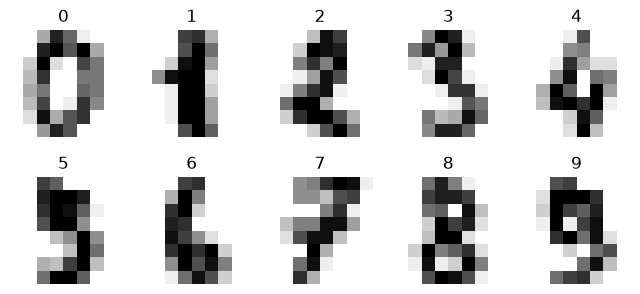

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for ax, img, lab in zip(axes.ravel(), d.images[:10], d.target[:10]):
  ax.imshow(img, cmap="gray_r")
  ax.set_title(lab)
  ax.axis("off")
plt.show()

In [6]:
X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
Xtr, Xval, ytr, yval = train_test_split(X_tv, y_tv, test_size=0.25, random_state=42, stratify=y_tv)

Xtr, Xval, X_te = Xtr / 16.0, Xval / 16.0, X_te / 16.0
print(Xtr.shape, Xval.shape, X_te.shape)
print(Xtr.max(), round(Xtr.mean(), 4))
print("majority baseline (val):", round(np.bincount(yval).max() / len(yval), 4))

(1077, 64) (360, 64) (360, 64)
1.0 0.3065
majority baseline (val): 0.1028


In [7]:
class DigitsDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32).reshape(-1, 1, 8, 8)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds, val_ds, test_ds = DigitsDataset(Xtr, ytr), DigitsDataset(Xval, yval), DigitsDataset(X_te, y_te)
print(len(train_ds), len(val_ds), len(test_ds))
print(train_ds[0][0].shape, train_ds[0][0].dtype, train_ds[0][1], train_ds[0][1].dtype) 

1077 360 360
torch.Size([1, 8, 8]) torch.float32 tensor(3) torch.int64


In [8]:
def new_train_loader():
    return DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(42))

test_loader = DataLoader(test_ds, batch_size=256)
val_loader = DataLoader(val_ds, batch_size=256)

xb, yb = next(iter(new_train_loader()))
print(xb.shape, yb.shape, xb.dtype, yb.dtype)
print(len(new_train_loader()), len(val_loader))
print("rows in the last train batch:", len(train_ds) - (len(new_train_loader()) - 1) * 64)

torch.Size([64, 1, 8, 8]) torch.Size([64]) torch.float32 torch.int64
17 2
rows in the last train batch: 53


In [9]:
loss_fn = nn.CrossEntropyLoss()

def run_epoch(model, loader, opt=None):
    train = opt is not None
    model.train() if train else model.eval()
    tot, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if train:
                loss.backward()
                opt.step()
                opt.zero_grad()
            tot += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return tot / n, correct / n 

def train_model(model, opt, epochs):
  loader = new_train_loader()
  h = {"tl": [], "ta": [], "vl": [], "va": []}
  best = {"vl": float("inf")}
  for e in range(1, epochs + 1):
    tl_, ta = run_epoch(model, loader, opt)
    vl_, va = run_epoch(model, val_loader)
    h["tl"].append(tl_)
    h["ta"].append(ta)
    h["vl"].append(vl_)
    h["va"].append(va)

    if vl_ < best["vl"]:
      best = {"vl": vl_, "va": va, "epoch": e, "state": copy.deepcopy(model.state_dict())}
  return h, best

In [10]:
def mk_cnn():
    torch.manual_seed(42)
    return nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(128, 10))

cnn = mk_cnn()
print(sum(p.numel() for p in cnn.parameters()))
x = next(iter(val_loader))[0]
for layer in cnn:
    x = layer(x)
    print(layer.__class__.__name__, tuple(x.shape))

1370
Conv2d (256, 8, 8, 8)
ReLU (256, 8, 8, 8)
MaxPool2d (256, 8, 4, 4)
Flatten (256, 128)
Linear (256, 10)


In [13]:
h, best = train_model(cnn, torch.optim.Adam(cnn.parameters(), lr=0.01), 30)
print("best epoch", best["epoch"], "val loss", round(best["vl"], 4), "val acc", round(best["va"], 4))

best epoch 6 val loss 0.0528 val acc 0.9806


In [12]:
cnn.load_state_dict(best["state"])
tloss, tacc = run_epoch(cnn, test_loader)
print("CNN test accuracy:", round(tacc, 4), "| wrong images:", round((1 - tacc) * len(y_te)))

CNN test accuracy: 0.9667 | wrong images: 12


**Comparison: Day 16 MLP vs a small CNN (same split, same recipe)**

| model | parameters | best val acc | test acc | wrong images (of 360) |
|---|---|---|---|---|
| Day 16 model B (MLP) | 4,810 | 0.975 | 0.9639 | 13 |
| CNN (Conv2d 1-8, MaxPool, Linear 128-10) | 1,370 | 0.9722 | 0.9667 | 12 |

- Same data, same 60/20/20 split, same Adam (lr 0.01), same 30 epochs, same seed. Only the input shape (N, 1, 8, 8) and the model changed.
- One test image is 0.28 percent, so 12 against 13 wrong images is a tie.
- The CNN reaches the same accuracy with about 3.5 times fewer parameters, because one 3 x 3 kernel is shared across the whole image.

**PART 3.  QUESTIONS FOR YOUR NOTES**

- Q1  A 3 x 3 kernel on a 1-channel image has 9 weights and 1 bias.
- Q2  Give two reasons why a conv layer needs far fewer parameters than a Linear
    layer on the same image.
    * Weight sharing - It will look at small patches of the images, use the same set
                       of small weights. That tiny weights will slid across the image
                       and detects here and there.
    * Local connectivity - Each output pixel in a conv layer only connects to a small, 
                           local patch (3 x 3) of the input, whereas a       
                           Linear layer connects every input feature to every output neuron.
- Q3  Write the output-size formula and say what each letter means.
    * out = floor((n + 2p - k) / s) + 1
    * n=input_size, p=padding, k=kernal, s=stride
- Q4  What does padding do?  What does stride do?  What happens to the output
    size when each one increases?
    * Padding: does adds a border of zeros around the image. When padding increases, the output size increases.
    * Stride: Determines how many pixels the window jumps at a time. When stride increases, the output size decreases (because it skips more steps).
- Q5  Pooling has 0 learnable parameters.  What is it for?
    * it is for shrinks the feature map by summarizing each block with one number.
- Q6  In the shape (N, C, H, W), what is each letter?  What was the shape of your
    Day 16 input, and what is the difference?
    * N=batch_size, C=channels, H=height, W=width
    * (N, 64), the difference is that Day 16 inputs were flat 2D matrices lacking spatial dimensions, whereas CNN tensors are 4D structures that explicitly preserve spatial layout (H, W) and multi-channel features (C).
- Q7  Why is there a ReLU after each convolution?
    * To introduce non-linearity. Without activation functions like ReLU, stacking multiple linear operations (convolutions) mathematically collapses into a single linear transformation
- Q8  What does the kernel  [[0,0,0],[0,1,0],[0,0,0]]  do to an image?
    * It does not change anything since it will multiply by 0.